# 06 · Imbalance Comparison

About 1 attempt in 4 is missed. The course (lesson 11) gives four options: oversample the minority class, create synthetic
minority rows (SMOTE), overweight the minority class (`class_weight`), or change the threshold.
This notebook compares the first three on the **training data with cross-validation**, so the test set stays untouched.

Resampling sits inside imblearn's `make_pipeline`, so it only ever touches the training folds.

In [1]:
import sys, json
sys.path.append('../src')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from clean import load_attempts
from prep import split, tune_sample, linear_preprocessor, tree_preprocessor, RANDOM_STATE

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
from imblearn.pipeline import make_pipeline
from imblearn.over_sampling import RandomOverSampler, SMOTE

sns.set_theme(style='whitegrid')
attempts = load_attempts()
X_train, X_test, y_train, y_test = split(attempts)
del attempts
X_tune, y_tune = tune_sample(X_train, y_train)
best = json.load(open('../results/best_params.json'))
rf_params = {k.replace('model__', ''): v for k, v in best['random_forest'].items()}
rf_params['n_estimators'] = 150          # fewer trees keep the comparison fast; the ranking of methods does not change
print('Random Forest params:', rf_params)
print('comparison sample:', X_tune.shape, f'make rate {y_tune.mean():.1%}')

Random Forest params: {'min_samples_leaf': 5, 'max_features': 0.3, 'max_depth': 12, 'n_estimators': 150}
comparison sample: (100000, 22) make rate 74.5%


## Set-up

- Two models: **Logistic Regression** (readable) and **Random Forest** (the strongest model that has a `class_weight` option; Gradient Boosting has none).
- **SMOTE** creates synthetic rows by mixing neighbours, which only makes sense for numbers, so it runs **after** the preprocessor (scaled numbers and one-hot columns), as in the lesson 11 notebook.
- Oversampling brings the missed class up to **the same size** as the made class (`sampling_strategy=1.0`).
- 3-fold stratified cross-validation on the 100,000-attempt tuning sample; metrics at the default 0.5 threshold, plus ROC-AUC.
- The positive class for recall / precision here is **missed** (`pos_label=0`), the class we want to catch.

In [2]:
def ros():
    return RandomOverSampler(sampling_strategy=1.0, random_state=RANDOM_STATE)

def smote():
    return SMOTE(sampling_strategy=1.0, random_state=RANDOM_STATE)

lr = lambda **kw: LogisticRegression(max_iter=2000, C=1, **kw)
rf = lambda **kw: RandomForestClassifier(n_jobs=-1, random_state=RANDOM_STATE, **rf_params, **kw)

setups = {
    ('Logistic Regression', 'none'):              make_pipeline(linear_preprocessor(), lr()),
    ('Logistic Regression', 'class_weight'):      make_pipeline(linear_preprocessor(), lr(class_weight='balanced')),
    ('Logistic Regression', 'RandomOverSampler'): make_pipeline(ros(), linear_preprocessor(), lr()),
    ('Logistic Regression', 'SMOTE'):             make_pipeline(linear_preprocessor(), smote(), lr()),
    ('Random Forest', 'none'):                    make_pipeline(tree_preprocessor(), rf()),
    ('Random Forest', 'class_weight'):            make_pipeline(tree_preprocessor(), rf(class_weight='balanced')),
    ('Random Forest', 'RandomOverSampler'):       make_pipeline(ros(), tree_preprocessor(), rf()),
}

In [3]:
from sklearn.metrics import make_scorer, recall_score, precision_score, f1_score

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    'roc_auc': 'roc_auc',
    'balanced_accuracy': 'balanced_accuracy',
    'recall_missed': make_scorer(recall_score, pos_label=0),
    'precision_missed': make_scorer(precision_score, pos_label=0, zero_division=0),
    'f1_missed': make_scorer(f1_score, pos_label=0),
}
rows = []
for (model, method), pipe in setups.items():
    s = cross_validate(pipe, X_tune, y_tune, cv=cv, scoring=scoring, n_jobs=1 if model == 'Random Forest' else -1)
    rows.append({'model': model, 'imbalance_method': method, **{m: s[f'test_{m}'].mean() for m in scoring}})
    print(f'{model:20s} {method:18s} ROC-AUC {rows[-1]["roc_auc"]:.4f}  recall(missed) {rows[-1]["recall_missed"]:.3f}')
imb = pd.DataFrame(rows).round(4)
imb

/usr/local/lib/python3.13/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [4] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.13/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [4] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


Logistic Regression  none               ROC-AUC 0.7625  recall(missed) 0.286


/usr/local/lib/python3.13/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [4] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.13/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [4] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


Logistic Regression  class_weight       ROC-AUC 0.7628  recall(missed) 0.694


/usr/local/lib/python3.13/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [4] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.13/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [4] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


Logistic Regression  RandomOverSampler  ROC-AUC 0.7627  recall(missed) 0.695


... (2 outputs left out)

Random Forest        none               ROC-AUC 0.7694  recall(missed) 0.312


Random Forest        class_weight       ROC-AUC 0.7692  recall(missed) 0.691


Random Forest        RandomOverSampler  ROC-AUC 0.7680  recall(missed) 0.678


,model,imbalance_method,roc_auc,balanced_accuracy,recall_missed,precision_missed,f1_missed
0,Logistic Regression,none,0.7625,0.6092,0.2862,0.5909,0.3856
1,Logistic Regression,class_weight,0.7628,0.7020,0.6937,0.4505,0.5462
2,Logistic Regression,RandomOverSampler,0.7627,0.7021,0.6947,0.4502,0.5463
3,Logistic Regression,SMOTE,0.7614,0.7010,0.6866,0.4523,0.5453
4,Random Forest,none,0.7694,0.6198,0.3124,0.5947,0.4096
5,Random Forest,class_weight,0.7692,0.7036,0.6908,0.4547,0.5484
6,Random Forest,RandomOverSampler,0.7680,0.7021,0.6781,0.4588,0.5473


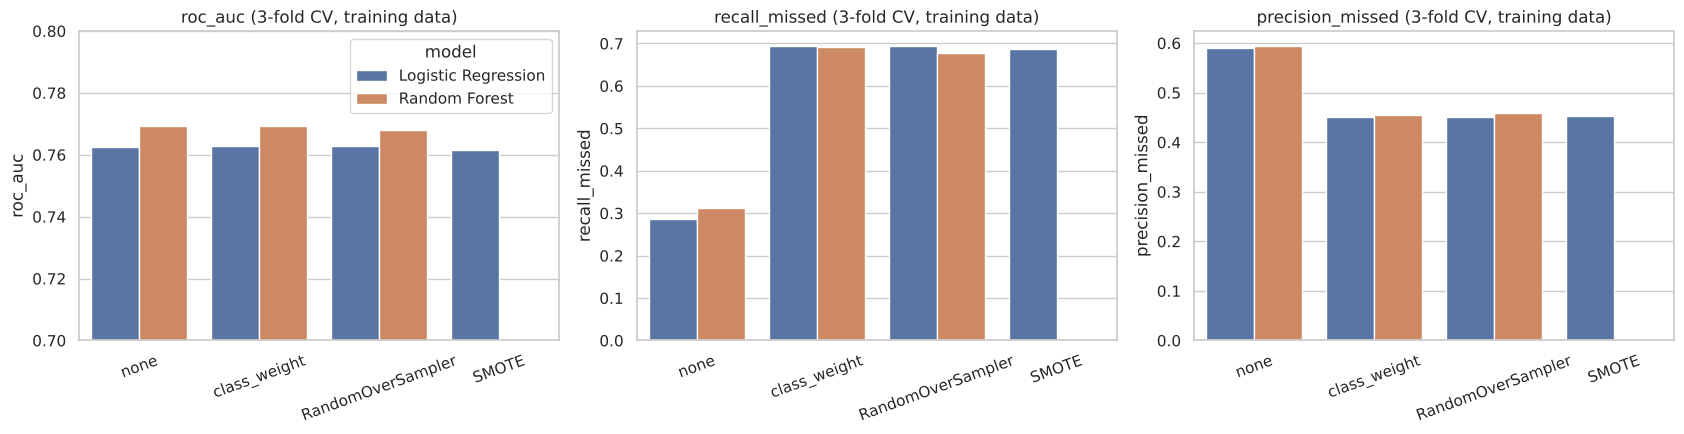

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, metric in zip(axes, ['roc_auc', 'recall_missed', 'precision_missed']):
    sns.barplot(data=imb, x='imbalance_method', y=metric, hue='model', ax=ax)
    ax.set_title(f'{metric} (3-fold CV, training data)')
    ax.set_xlabel(''); ax.tick_params(axis='x', rotation=20)
    if metric == 'roc_auc':
        ax.set_ylim(0.7, 0.8)
    if ax is not axes[0]:
        ax.get_legend().remove()
plt.tight_layout(); plt.show()

## What this shows

- **No method improves ROC-AUC.** Logistic Regression stays at 0.761–0.763 and Random Forest at 0.768–0.769 whatever the handling; SMOTE is slightly worse (0.761). Balancing does not make the model rank attempts better.
- What balancing changes is the **recall vs precision trade-off at the 0.5 threshold**. Random Forest goes from catching 31% of misses (precision 59%) with no handling to 69% (precision 45%) with class weights: the model simply warns more often.
- With a 75 / 25 split the imbalance is **moderate**, and moving the threshold (lesson 10, option 4 in lesson 11) does the same job **without synthetic rows or reweighting**, and lets the user pick the trade-off directly.

**Decision:** keep the models **without resampling** (best ROC-AUC, simplest pipeline, and probabilities that stay on the real scale, which notebook 07 needs to check they can be trusted) and handle the imbalance by **tuning the threshold** in notebook 07.

In [5]:
imb.to_csv('../results/imbalance_cv.csv', index=False)